In [7]:
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd
from sklearn.model_selection import train_test_split 

In [8]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [10]:
df_train.head().T

,4740,1452,2846,4670,168
lead_source,paid_ads,paid_ads,NaN,paid_ads,organic_search
industry,technology,retail,finance,finance,finance
employment_status,employed,employed,employed,employed,employed
location,asia,asia,NaN,NaN,asia
annual_income,80198.0,50548.0,76300.0,80371.0,73567.0
number_of_courses_viewed,5,2,0,2,2
interaction_count,9,5,3,6,4
lead_score,0.91,0.48,0.42,0.49,0.48
converted,1,0,0,0,1


In [16]:
df_train.isnull().sum()

lead_source                  90
industry                    152
employment_status           118
location                    125
annual_income               224
number_of_courses_viewed      0
interaction_count             0
lead_score                   26
converted                     0
dtype: int64

In [17]:
df_train.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [ ]:
categorical = list(df_train.dtypes[df_train.dtypes == 'str'].index)
df_train[categorical] = df_train[categorical].fillna('NA')
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
df_train[numerical] = df_train[numerical].fillna(0.0)




y_train = df_train['converted'].values

In [54]:
categorical = list(df_val.dtypes[df_val.dtypes == 'str'].index)
df_val[categorical] = df_val[categorical].fillna('NA')
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
df_val[numerical] = df_val[numerical].fillna(0.0)




y_val = df_val['converted'].values

In [55]:
categorical = list(df_full_train.dtypes[df_full_train.dtypes == 'str'].index)
df_full_train[categorical] = df_full_train[categorical].fillna('NA')
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
df_full_train[numerical] = df_full_train[numerical].fillna(0.0)




y_full_train = df_full_train['converted'].values

In [56]:
from sklearn.metrics import roc_auc_score

### Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score` 
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income` <-- the answer 0.788


In [57]:
scores =[]


for feature in numerical:
    auc = roc_auc_score(y_train,  df_train[feature] )
    if auc < 0.5:
       auc = roc_auc_score(y_train, -df_train[feature])

    scores.append((feature, auc))
    
print('Numerical features:')
for feature, auc in sorted(scores, key=lambda x: x[1], reverse=True):
    print(f'{feature}: {auc:.3f}')



Numerical features:
lead_score: 0.788
interaction_count: 0.765
number_of_courses_viewed: 0.723
annual_income: 0.608


### Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732   <-- the answer
- 0.832


In [63]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

In [104]:
def train(df_train, y_train, C=1.0):

    dv = DictVectorizer(sparse=False)
    train_dicts = df_train[categorical + numerical].to_dict(orient='records')
    X_train = dv.fit_transform(train_dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [105]:
dv, model = train(df_train, y_train)

In [106]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred

In [107]:
ytrain_pred = predict(df_train, dv, model)


In [108]:
y_val_pred = predict(df_val, dv, model)

In [109]:
auc = roc_auc_score(y_val, y_val_pred)
round(auc, 3)
print('the answer is: ' + str(round(auc, 3)))

the answer is: 0.721


In [110]:
auc = roc_auc_score(y_train, ytrain_pred)
round(auc, 3)

0.735

### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73 <-- Answer
* 0.83

In [111]:
ts = np.linspace(0, 1, 101)

scores = []
for t in ts:

    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    pred_positive = (y_val_pred >= t)
    pred_negative = (y_val_pred < t)

    tp = (pred_positive & actual_positive).sum()
    fp = (pred_positive & actual_negative).sum()

    fn = (pred_negative & actual_positive).sum()
    tn = (pred_negative & actual_negative).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    scores.append((t, r, p))

columns = ['threshold', 'recall', 'precision']
df_scores = pd.DataFrame(scores, columns=columns)





/tmp/ipykernel_8167/3369579686.py:19: RuntimeWarning: invalid value encountered in scalar divide
  p = tp / (tp + fp)


In [112]:
df_scores['diff'] = abs(df_scores['precision'] - df_scores['recall'])

df_scores[df_scores['diff'] == df_scores['diff'].min()]

,threshold,recall,precision,diff
61,0.61,0.724576,0.7125,0.012076


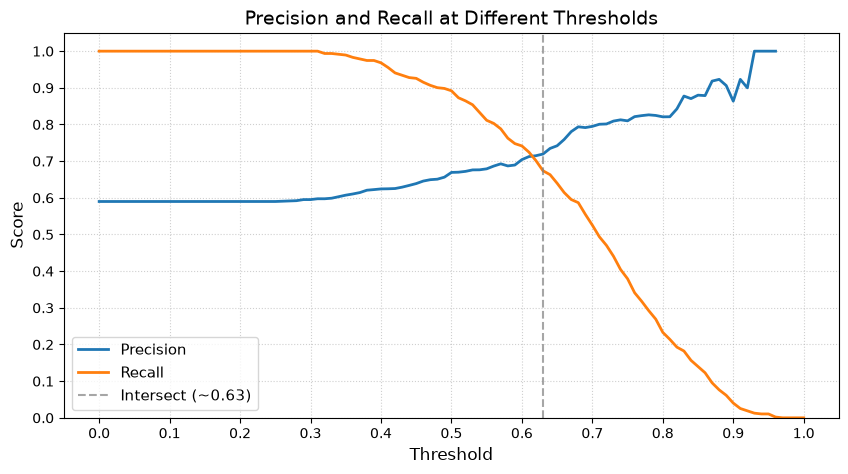

In [130]:
plt.figure(figsize=(10, 5))

# Plot precision and recall
plt.plot(
    df_scores["threshold"],
    df_scores["precision"],
    label="Precision",
    linewidth=2
)
plt.plot(
    df_scores["threshold"],
    df_scores["recall"],
    label="Recall",
    linewidth=2
)

df_scores[df_scores["recall"] == df_scores["precision"]]
intersect_threshold = 0.63

plt.axvline(
    x=intersect_threshold, 
    color='gray', 
    linestyle='--', 
    alpha=0.7, 
    label=f'Intersect (~{intersect_threshold})'
)

# Add more granular markings/ticks on the axes
plt.xticks(np.arange(0, 1.1, 0.1))  # Marks every 0.1 from 0 to 1 on the X-axis
plt.yticks(np.arange(0, 1.1, 0.1))  # Marks every 0.1 from 0 to 1 on the Y-axis

# Labels, title, grid, and legend
plt.xlabel("Threshold", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.title("Precision and Recall at Different Thresholds", fontsize=14)

plt.grid(True, linestyle=":", alpha=0.6)
plt.ylim(0, 1.05)
plt.legend(fontsize=11)

plt.show()

### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41 <-- answer 
- 0.61
- 0.81

In [127]:
df_scores['f1']= 2 * df_scores['recall'] * df_scores['precision'] / (df_scores['recall'] + df_scores['precision'])

df_scores['f1'].max()

np.float64(0.7647593097184378)

In [128]:
best_f1 = df_scores['f1'].max()

df_scores[df_scores['f1'] == best_f1]

,threshold,recall,precision,diff,f1
50,0.5,0.891949,0.669316,0.222633,0.764759


### Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007 <-- Answer
- 0.013
- 0.060

In [116]:
!pip install tqdm

In [117]:
from sklearn.model_selection import KFold
from tqdm.notebook import tqdm

In [124]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
n_splits = 5

kfold.split(df_full_train)

for C in [0.000001, 0.001, 1]:
    auc_scores_cv = []
    for train_idx, val_idx in tqdm(kfold.split(df_full_train), total=n_splits):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['converted'].values
        y_val = df_val['converted'].values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        auc_scores_cv.append(auc)

    print(f'C={C} mean: {np.mean(auc_scores_cv):.3f} +/-  STD: {np.std(auc_scores_cv):.3f}')
    


  0%|          | 0/5 [00:00<?, ?it/s]

C=1e-06 mean: 0.617 +/-  STD: 0.019


  0%|          | 0/5 [00:00<?, ?it/s]

C=0.001 mean: 0.749 +/-  STD: 0.010


  0%|          | 0/5 [00:00<?, ?it/s]

C=1 mean: 0.732 +/-  STD: 0.007


In [126]:
auc_scores_cv


[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [123]:

round(np.std(auc_scores_cv), 3)

np.float64(0.007)

### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1 <-- Answer

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.